Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


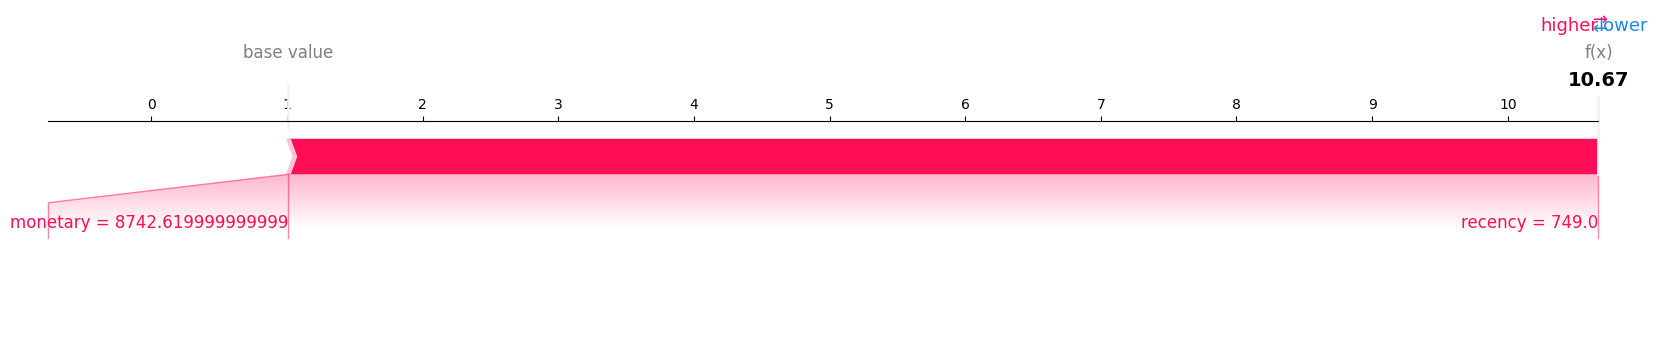

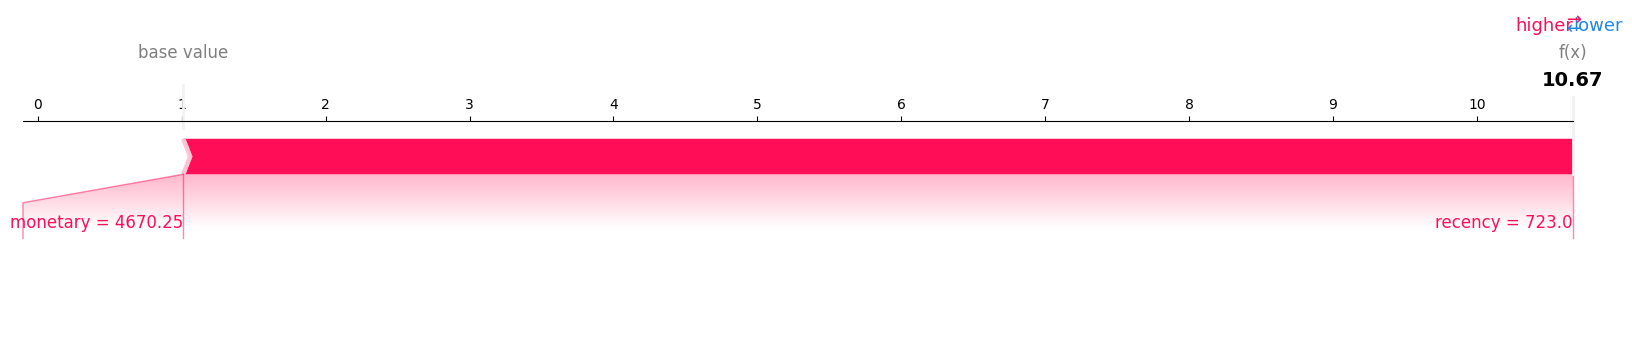

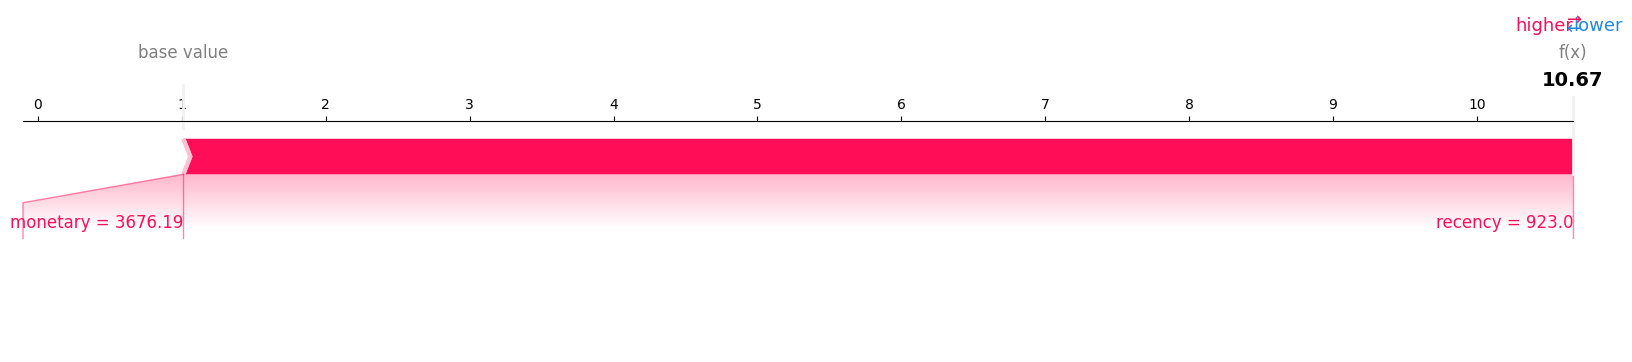

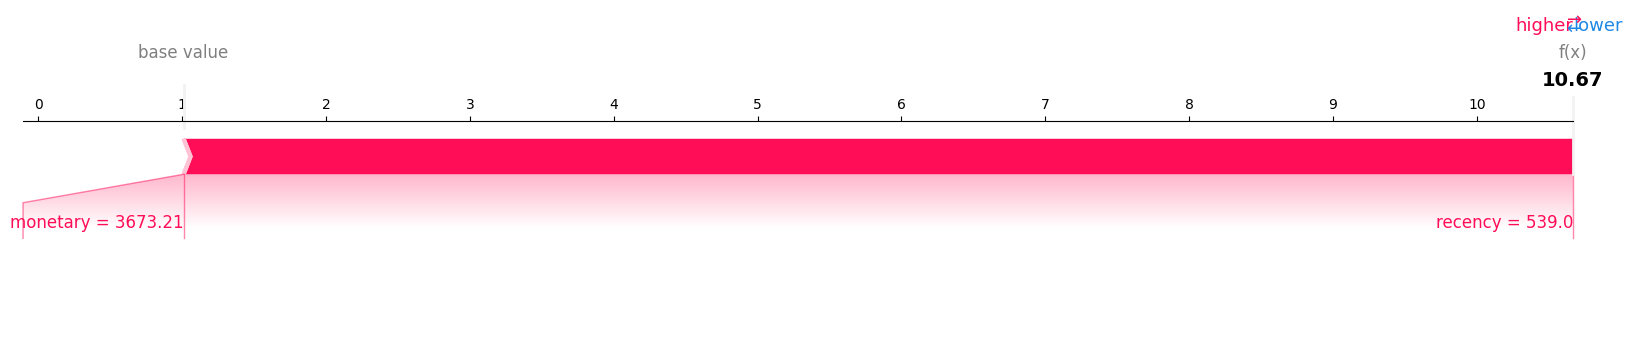

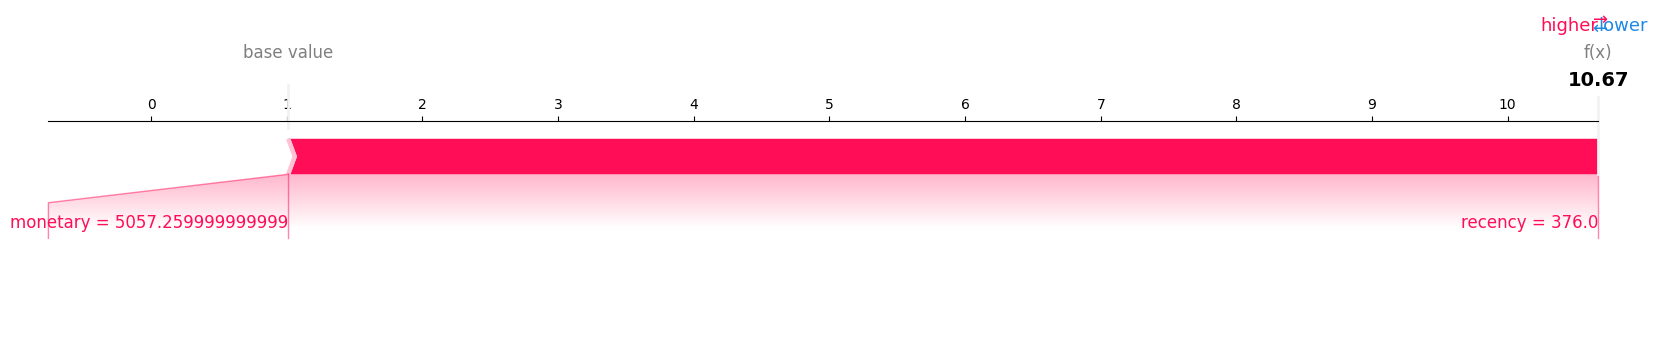

/usr/local/lib/python3.13/dist-packages/shap/plots/_force_matplotlib.py:107: RuntimeWarning: divide by zero encountered in scalar divide
  feature_contribution = np.abs(float(feature[0]) - pre_val) / np.abs(total_effect)


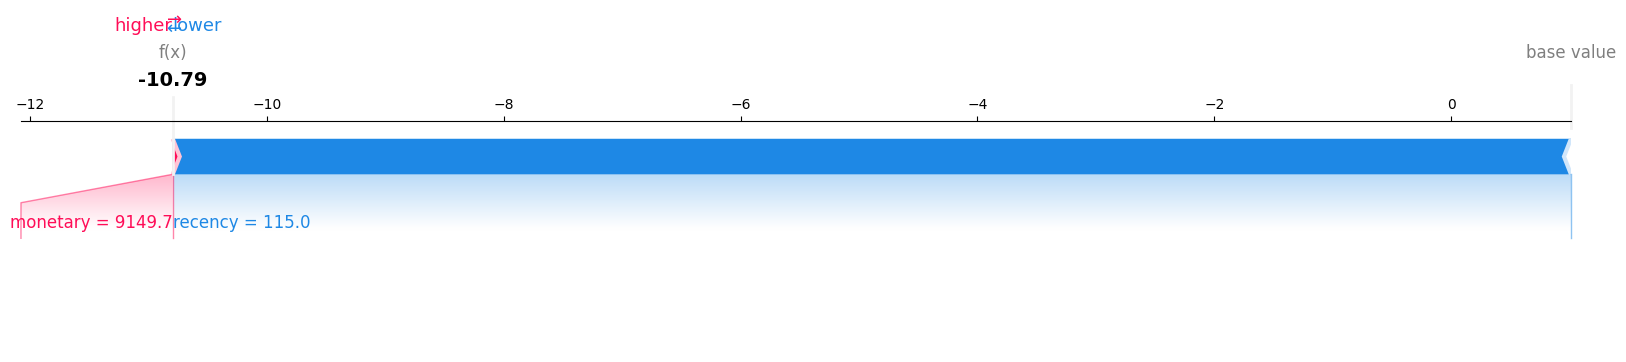

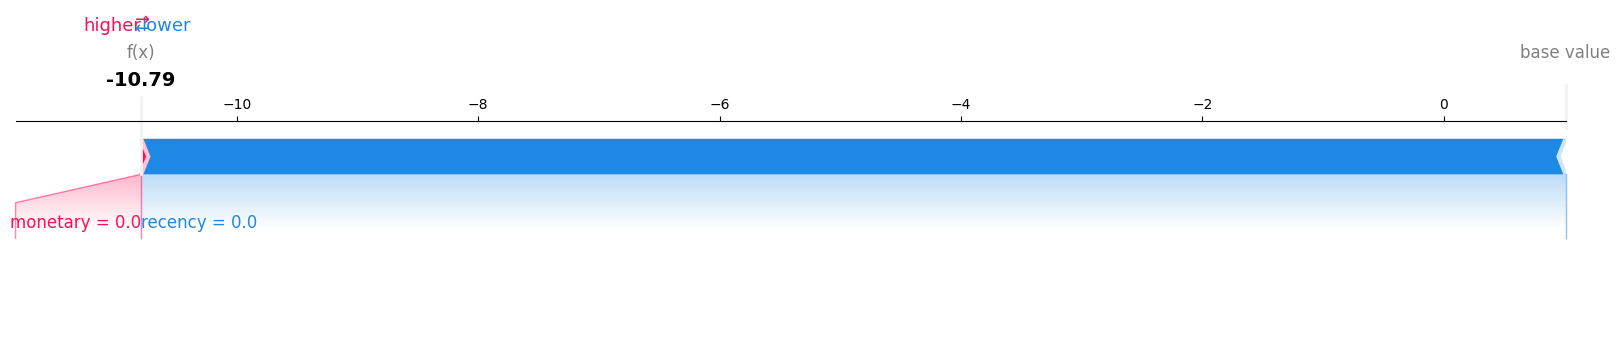

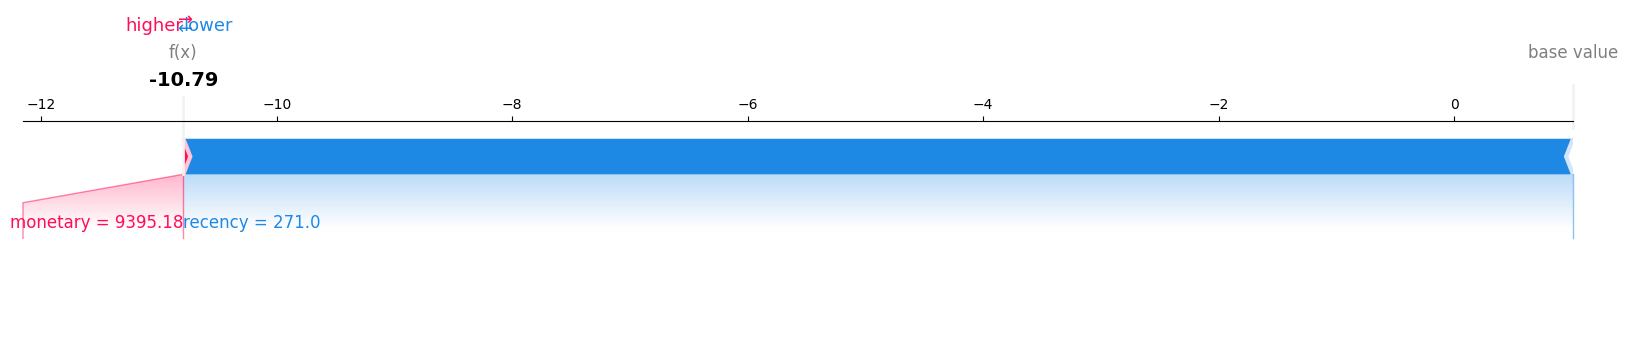

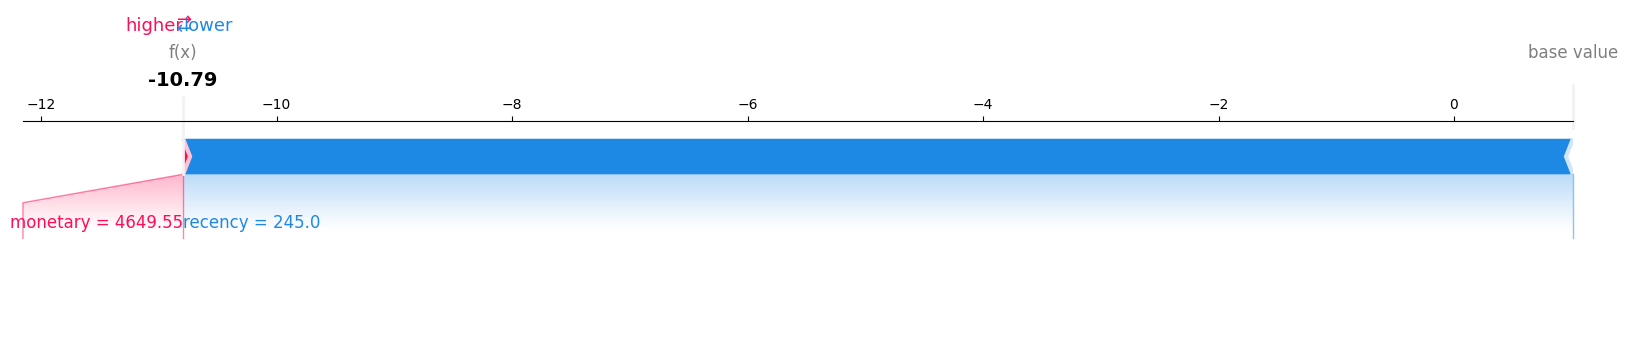

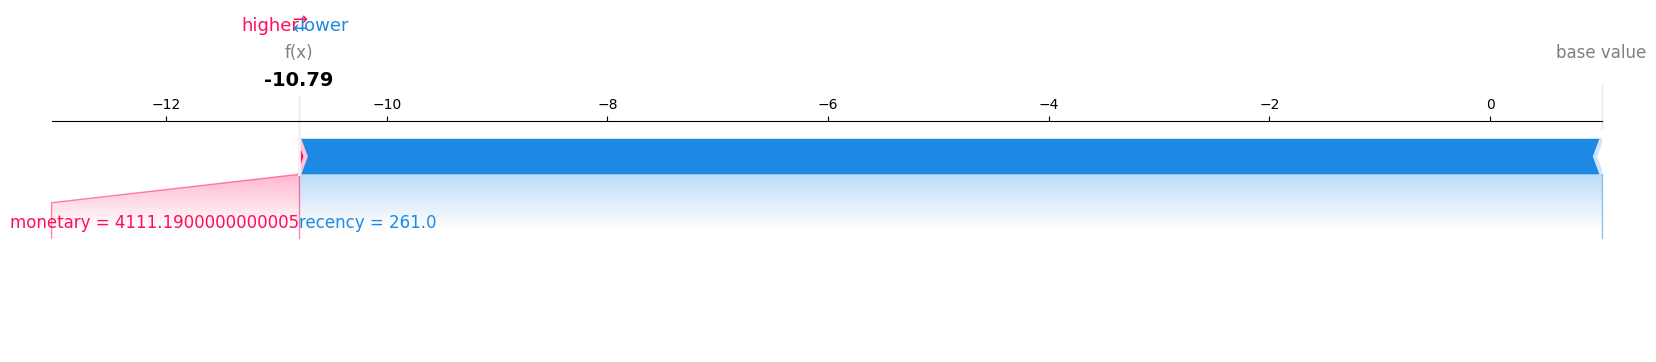

✅ Customer-level SHAP plots saved for top 5 churned and top 5 retained customers


In [14]:
# Phase 10: Model Interpretation — Customer Churn

from google.colab import drive
drive.mount('/content/drive')

import os, sys, joblib, shap
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Setup paths
# -----------------------------
project_dir = "/content/drive/MyDrive/Cape Stone Project 2026"
model_path = f"{project_dir}/models/final_model.pkl"
features_path = f"{project_dir}/data/processed/features.csv"
viz_dir = f"{project_dir}/visualizations"

os.makedirs(viz_dir, exist_ok=True)

# -----------------------------
# Safety checks
# -----------------------------
if not os.path.exists(model_path) or os.path.getsize(model_path) == 0:
    raise FileNotFoundError("❌ Model file missing or empty. Please rerun Phase 9.")

if not os.path.exists(features_path):
    raise FileNotFoundError("❌ Features file missing. Please rerun Phase 8.")

# -----------------------------
# Load model and features
# -----------------------------
model = joblib.load(model_path)
features = pd.read_csv(features_path)

numeric_features = features.select_dtypes(include=["number"]).copy()
X = numeric_features.drop("churn_flag", axis=1)
y = numeric_features["churn_flag"]

# -----------------------------
# Feature Importance
# -----------------------------
importances = model.feature_importances_
importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": importances
}).sort_values(by="importance", ascending=False)

plt.figure(figsize=(10,6))
plt.barh(importance_df["feature"], importance_df["importance"], color="skyblue")
plt.title("Feature Importance (Gradient Boosting)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.savefig(f"{viz_dir}/feature_importance_interpretation.png")
plt.close()

# -----------------------------
# SHAP Values
# -----------------------------
explainer = shap.Explainer(model, X)
shap_values = explainer(X)

# Global summary plot
shap.summary_plot(shap_values, X, show=False)
plt.savefig(f"{viz_dir}/shap_summary.png")
plt.close()

# Dependence plot (example: recency)
shap.dependence_plot("recency", shap_values.values, X, show=False)
plt.savefig(f"{viz_dir}/shap_dependence_recency.png")
plt.close()

# -----------------------------
# Customer-level SHAP Force Plots (Top 5 churned & retained)
# Customer-level SHAP Force Plots (Top 5 churned & retained)

churned_customers = features[features["churn_flag"] == 1].head(5)
retained_customers = features[features["churn_flag"] == 0].head(5)

def save_customer_plot(cid, idx, label):
    shap.force_plot(
        explainer.expected_value,
        shap_values.values[idx],   # ✅ use raw array of SHAP values
        X.iloc[idx],
        matplotlib=True
    )
    plt.savefig(f"{viz_dir}/customer_explanation_{cid}_{label}.png")
    plt.close()

for _, row in churned_customers.iterrows():
    cid = row["customer_id"]
    idx = features[features["customer_id"] == cid].index[0]
    save_customer_plot(cid, idx, "churned")

for _, row in retained_customers.iterrows():
    cid = row["customer_id"]
    idx = features[features["customer_id"] == cid].index[0]
    save_customer_plot(cid, idx, "retained")

print("✅ Customer-level SHAP plots saved for top 5 churned and top 5 retained customers")



In [15]:
import os

model_path = "/content/drive/MyDrive/Cape Stone Project 2026/models/final_model.pkl"
print("Exists:", os.path.exists(model_path))
print("Size (bytes):", os.path.getsize(model_path))


Exists: True
Size (bytes): 63000
